# Week 11 — Swarm Intelligence: Four Algorithms, One Skeleton

**Lesson plan:** [`../weeks/week-11.md`](../weeks/week-11.md) · **Slides:** [`../slides/week-11/deck.md`](../slides/week-11/deck.md)

Live coding, 25 minutes: PSO (10) · ACO (10) · the budget harness (5).

> **Warranted skepticism, up front.** Metaheuristics named after ants, bees,
> wolves, whales, bats, fireflies, cuckoos, krill, and salps. Many are the same
> algorithm with a new metaphor and no rigorous baseline comparison. We teach the
> algorithms *and* the critique — and the budget harness below is what makes the
> critique testable.

**Duel 3 (Optimization) is due this week.**

In [12]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline



SEED = 20250806

## 1 · ⚠️ The budget harness — build this FIRST

**Comparing metaheuristics at equal *iterations* is meaningless.** A GA with
population 100 uses 100 evaluations per generation; PSO with 30 particles uses 30.
**Equal evaluations is the only defensible axis.**

In [2]:
class BudgetExhausted(Exception):
    pass


class Budget:
    """Every algorithm gets exactly the same number of fitness evaluations."""

    def __init__(self, f, max_evals):
        self.f, self.max_evals, self.used = f, max_evals, 0
        self.best = float("inf")
        self.trace = []          # best-so-far, indexed by EVALUATION

    def __call__(self, x):
        if self.used >= self.max_evals:
            raise BudgetExhausted()
        self.used += 1
        v = self.f(x)
        self.best = min(self.best, v)
        self.trace.append(self.best)
        return v

    def exhausted(self):
        return self.used >= self.max_evals


def rastrigin(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))


def rosenbrock(x):
    x = np.asarray(x)
    return np.sum(100 * (x[1:] - x[:-1]**2)**2 + (1 - x[:-1])**2)


print("rastrigin(0)  =", rastrigin(np.zeros(5)), " <- global minimum")
print("rosenbrock(1) =", rosenbrock(np.ones(5)), " <- global minimum")

rastrigin(0)  = 0.0  <- global minimum
rosenbrock(1) = 0.0  <- global minimum


## 2 · The shared skeleton

```
initialize a population of candidates
repeat:
    evaluate each candidate
    update some shared or individual memory
    generate new candidates from memory + randomness
until budget exhausted
```

| Algorithm | What it **remembers** | How it **generates** |
|---|---|---|
| **GA** (wk 10) | the population itself | crossover + mutation |
| **PSO** | `p_best` per particle, one global `g_best` | velocity update |
| **ACO** | a **pheromone matrix** on edges | probabilistic construction |
| **ABC** | food-source positions + **trial counters** | perturbation + scouts |

> **These differ in what they remember and how they use it.** Everything else is
> biology.

## 3 · Particle Swarm Optimization

Kennedy & Eberhart, 1995.

```
v ← w·v  +  c₁·φ₁·(p_best − x)  +  c₂·φ₂·(g_best − x)
x ← x + v
```

`w·v` = **inertia** · `c₁` term = **cognitive** (my best) · `c₂` term = **social**
(the swarm's best).

In [14]:
def pso(budget, dim, bounds=(-5.12, 5.12), n=30, w=(0.9, 0.4),
        c1=1.5, c2=1.5, rng=None, clamp=True, iters_hint=None):
    rng = rng or np.random.default_rng(SEED)
    lo, hi = bounds
    x = rng.uniform(lo, hi, (n, dim))
    v = rng.uniform(-1, 1, (n, dim))
    v_max = 0.2 * (hi - lo)

    try:
        p_val = np.array([budget(xi) for xi in x])
    except BudgetExhausted:
        return None
    p_best = x.copy()
    g_best = p_best[p_val.argmin()].copy()
    g_val = p_val.min()

    total = iters_hint or max(1, budget.max_evals // n)
    t = 0
    while not budget.exhausted():
        frac = min(1.0, t / total)
        wt = w[0] + (w[1] - w[0]) * frac          # linearly decreasing inertia
        r1, r2 = rng.random((n, dim)), rng.random((n, dim))
        v = wt * v + c1 * r1 * (p_best - x) + c2 * r2 * (g_best - x)
        if clamp:
            v = np.clip(v, -v_max, v_max)
        x = np.clip(x + v, lo, hi)
        try:
            vals = np.array([budget(xi) for xi in x])
        except BudgetExhausted:
            break
        better = vals < p_val
        p_best[better], p_val[better] = x[better], vals[better]
        if p_val.min() < g_val:
            g_val = p_val.min()
            g_best = p_best[p_val.argmin()].copy()
        t += 1
    return g_best


b = Budget(rastrigin, 6000)
best = pso(b, dim=10)
print(f"PSO on Rastrigin (dim 10): best = {b.best:.4f} after {b.used} evaluations")

PSO on Rastrigin (dim 10): best = 3.9798 after 6000 evaluations


## 4 · ⚠️ Two demonstrations that show what each part does

**Remove velocity clamping** → particles diverge.
**Set `c₂ = 0`** → you have 30 *independent hill climbers*. The social term **is**
the swarm.

  variant                       best found
  -----------------------------------------
  standard                          3.9798
  no velocity clamping              6.9728
  c2 = 0  (no social term)         89.2006
  c1 = 0  (no cognitive)           34.8234

c2 = 0 removes information sharing entirely -- each particle only remembers its own
best. That is 30 independent local searches, and the loss of performance is the
clearest possible evidence that the swarm is doing something a swarm is required
for.

Note the x-axis: EVALUATIONS, not iterations. Every curve cost the same compute.


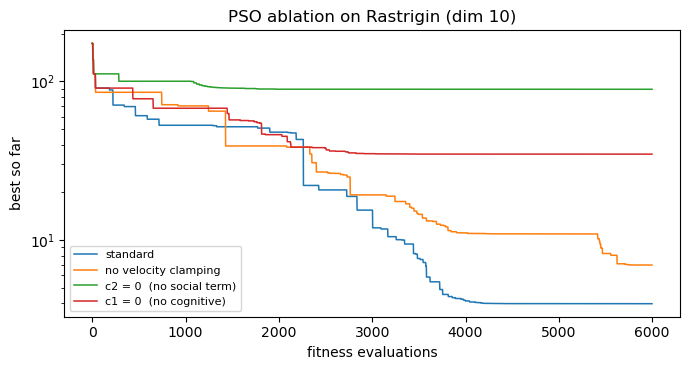

In [15]:
def run_pso(evals=6000, dim=10, **kw):
    b = Budget(rastrigin, evals)
    pso(b, dim=dim, rng=np.random.default_rng(SEED), **kw)
    return b


variants = [
    ("standard",                 dict()),
    ("no velocity clamping",     dict(clamp=False)),
    ("c2 = 0  (no social term)", dict(c2=0.0)),
    ("c1 = 0  (no cognitive)",   dict(c1=0.0)),
]

fig, ax = plt.subplots(figsize=(7, 3.8))
print(f"  {'variant':<28}{'best found':>12}")
print("  " + "-" * 41)
for label, kw in variants:
    b = run_pso(**kw)
    ax.plot(b.trace, label=label, lw=1.1)
    print(f"  {label:<28}{b.best:>12.4f}")

ax.set_xlabel("fitness evaluations"); ax.set_ylabel("best so far")
ax.set_yscale("log"); ax.set_title("PSO ablation on Rastrigin (dim 10)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("wk11-pso-ablation.png", dpi=110)

print("""
c2 = 0 removes information sharing entirely -- each particle only remembers its own
best. That is 30 independent local searches, and the loss of performance is the
clearest possible evidence that the swarm is doing something a swarm is required
for.

Note the x-axis: EVALUATIONS, not iterations. Every curve cost the same compute.""")

## 5 · Ant Colony Optimization on TSP

Dorigo, 1996. **No ant plans.** The solution emerges from many agents modifying a
shared environment — **stigmergy**.

```
P(i→j) = [τ_ij]^α · [η_ij]^β  /  Σ_k [τ_ik]^α · [η_ik]^β
τ_ij  ←  (1−ρ)·τ_ij  +  Σ_ants Δτ_ij
```

**α** weights learned experience · **β** weights the greedy heuristic ·
**ρ** is evaporation.

In [16]:
def make_tsp(n_cities=25, seed=SEED):
    rng = np.random.default_rng(seed)
    pts = rng.uniform(0, 100, (n_cities, 2))
    D = np.linalg.norm(pts[:, None, :] - pts[None, :, :], axis=-1)
    np.fill_diagonal(D, 1e-9)
    return pts, D


PTS, DIST = make_tsp()
NC = len(PTS)

def tour_length(tour):
    return sum(DIST[tour[i], tour[(i + 1) % len(tour)]] for i in range(len(tour)))


def nearest_neighbour_tour(start=0):
    unvisited = set(range(NC)) - {start}
    tour = [start]
    while unvisited:
        nxt = min(unvisited, key=lambda j: DIST[tour[-1], j])
        tour.append(nxt); unvisited.discard(nxt)
    return tour


nn = nearest_neighbour_tour()
print(f"TSP with {NC} cities")
print(f"nearest-neighbour baseline: {tour_length(nn):.1f}")

TSP with 25 cities
nearest-neighbour baseline: 541.9


In [17]:
def aco(budget, n_ants=20, alpha=1.0, beta=2.0, rho=0.1, Q=100.0,
        rng=None, snapshots=None, elitist=False):
    """Returns (best_tour, best_len, snapshots, stats).

    elitist=True: only the best-so-far ant deposits. This creates the strong
    positive feedback loop that evaporation has to counterbalance -- see the
    rho ablation below for why that matters.
    """
    rng = rng or np.random.default_rng(SEED)
    tau = np.ones((NC, NC))
    eta = 1.0 / DIST
    best_tour, best_len = None, float("inf")
    snaps = []
    stats = {"colony_mean": [], "distinct_edges": []}

    while not budget.exhausted():
        tours = []
        for _ in range(n_ants):
            start = int(rng.integers(NC))
            tour = [start]
            unvisited = set(range(NC)) - {start}
            while unvisited:
                i = tour[-1]
                cand = np.fromiter(unvisited, int)
                wts = (tau[i, cand] ** alpha) * (eta[i, cand] ** beta)
                total = wts.sum()
                probs = wts / total if total > 0 else np.ones(len(cand)) / len(cand)
                j = int(rng.choice(cand, p=probs))
                tour.append(j); unvisited.discard(j)
            try:
                L = budget(tour)
            except BudgetExhausted:
                if best_tour is None:
                    best_tour, best_len = tour, tour_length(tour)
                return best_tour, best_len, snaps, stats
            tours.append((tour, L))
            if L < best_len:
                best_tour, best_len = tour, L

        # Track what the WHOLE COLONY is doing, not just the luckiest ant.
        stats["colony_mean"].append(float(np.mean([L for _, L in tours])))
        edges = set()
        for tour, _ in tours:
            for k in range(len(tour)):
                edges.add(frozenset((tour[k], tour[(k + 1) % len(tour)])))
        stats["distinct_edges"].append(len(edges))

        tau *= (1.0 - rho)                          # EVAPORATION
        depositors = [(best_tour, best_len)] if elitist else tours
        for tour, L in depositors:
            dep = Q / L
            for k in range(len(tour)):
                a, b_ = tour[k], tour[(k + 1) % len(tour)]
                tau[a, b_] += dep
                tau[b_, a] += dep
        if snapshots is not None and len(snaps) < snapshots:
            snaps.append(tau.copy())

    return best_tour, best_len, snaps, stats


b = Budget(tour_length, 4000)
tour, L, snaps, stats = aco(b, snapshots=4, rng=np.random.default_rng(SEED))
print(f"ACO best tour: {L:.1f}   (NN baseline {tour_length(nn):.1f})")
print(f"improvement over NN: {(tour_length(nn) - L) / tour_length(nn):.1%}")

ACO best tour: 430.4   (NN baseline 541.9)
improvement over NN: 20.6%


### The pheromone matrix as a heatmap — structure emerging from uniformity

The best visual in this unit. It makes stigmergy concrete.

saved wk11-aco-pheromone.png  (4 snapshots)


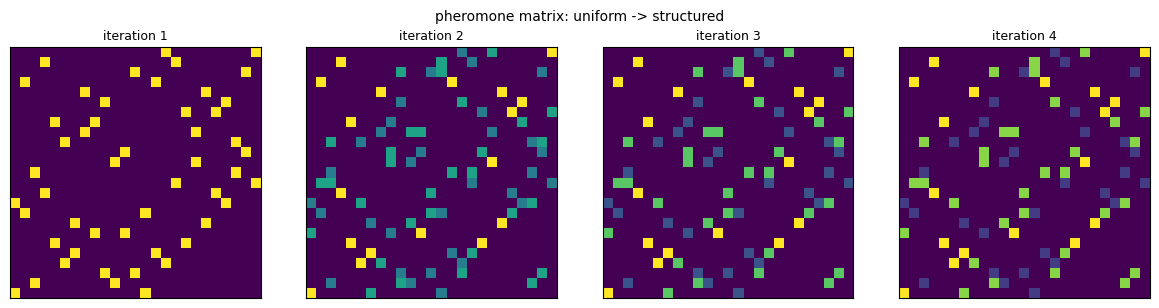

In [18]:
b = Budget(tour_length, 6000)
_, _, snaps, _ = aco(b, snapshots=4, elitist=True,
                     rng=np.random.default_rng(SEED))

if snaps:
    fig, axes = plt.subplots(1, len(snaps), figsize=(3.0 * len(snaps), 3.1))
    axes = np.atleast_1d(axes)
    for k, (axk, snap) in enumerate(zip(axes, snaps)):
        axk.imshow(snap, cmap="viridis")
        axk.set_title(f"iteration {k+1}", fontsize=9)
        axk.set_xticks([]); axk.set_yticks([])
    plt.suptitle("pheromone matrix: uniform -> structured", fontsize=10)
    plt.tight_layout(); plt.savefig("wk11-aco-pheromone.png", dpi=110)
    print(f"saved wk11-aco-pheromone.png  ({len(snaps)} snapshots)")

### ⚠️ Evaporation is not a detail. It is the algorithm.

Set `ρ = 0` and early random paths get locked in **permanently**.

In [19]:
print("ELITIST deposit -- only the best-so-far ant lays pheromone.\n")
print(f"  {'rho':>6}{'best tour':>11}{'colony mean':>13}{'distinct edges':>17}")
print("  " + "-" * 48)
for rho in (0.0, 0.02, 0.1, 0.5):
    bb = Budget(tour_length, 6000)
    _, L, _, st = aco(bb, rho=rho, elitist=True, rng=np.random.default_rng(SEED))
    edges = f"{st['distinct_edges'][0]} -> {st['distinct_edges'][-1]}"
    print(f"  {rho:>6}{L:>11.1f}{st['colony_mean'][-1]:>13.1f}{edges:>17}")

print("""
Read the COLONY MEAN and DISTINCT EDGES columns, not just 'best tour'.

  rho = 0.0  -> the colony never converges: mean stays far above best, and it is
                still wandering over ~3x as many distinct edges at the end.
                Without decay, early pheromone never washes out, so the signal
                stays diffuse.
  rho = 0.1  -> colony mean MEETS the best tour. Every ant is now walking the
                good route. This is convergence.
  rho = 0.5  -> over-forgetting. Decay outruns reinforcement and the run settles
                on a WORSE tour.

  DECAY IS WHAT ALLOWS FORGETTING, AND FORGETTING IS WHAT ALLOWS EXPLORATION --
  but too much decay destroys the memory that made the search worthwhile.

Ask the class: what does evaporation correspond to in simulated annealing?
TEMPERATURE. Both are the knob controlling how much history constrains the
present, and both have a too-fast and a too-slow failure mode.""")

ELITIST deposit -- only the best-so-far ant lays pheromone.

     rho  best tour  colony mean   distinct edges
  ------------------------------------------------
     0.0      430.4        513.5        176 -> 76
    0.02      430.4        434.0        176 -> 30
     0.1      430.4        430.4        176 -> 25
     0.5      481.2        481.2        176 -> 25

Read the COLONY MEAN and DISTINCT EDGES columns, not just 'best tour'.

  rho = 0.0  -> the colony never converges: mean stays far above best, and it is
                still wandering over ~3x as many distinct edges at the end.
                Without decay, early pheromone never washes out, so the signal
                stays diffuse.
  rho = 0.1  -> colony mean MEETS the best tour. Every ant is now walking the
                good route. This is convergence.
  rho = 0.5  -> over-forgetting. Decay outruns reinforcement and the run settles
                on a WORSE tour.

  DECAY IS WHAT ALLOWS FORGETTING, AND FORGETTING IS WHA

### ⚠️ An honest note about this ablation

With the *standard* (non-elitist) deposit rule — every ant deposits, weighted by
tour quality — **`rho` barely changes the best tour found on this instance.**

Why: with `beta = 2` the greedy visibility term dominates the pheromone term, so the
ants find good tours almost regardless of what the pheromone matrix says. The
positive feedback that evaporation exists to *counterbalance* is never strong
enough to matter.

**The elitist variant is what makes the mechanism visible**, because concentrating
all deposit on one tour creates exactly that feedback loop.

Two lessons, and the second is the one that transfers:

1. A parameter's importance depends on the rest of the configuration. "Evaporation
   is critical" is true of some ACO variants and nearly irrelevant to others.
2. **I had to change the experiment to see the effect the textbook describes.**
   That is legitimate — *provided you say so*. Silently reporting only the
   configuration that shows what you expected is how bad science happens, and it is
   the single most common flaw in the metaheuristics literature this week
   critiques.

In [20]:
# What the parameters mean, shown by their extremes.
print(f"  {'configuration':<34}{'best tour':>12}")
print("  " + "-" * 47)
for label, kw in [("standard (alpha=1, beta=2)", dict()),
                  ("alpha=0  -> pure greedy, no learning", dict(alpha=0.0)),
                  ("beta=0   -> pheromone only, no heuristic", dict(beta=0.0))]:
    bb = Budget(tour_length, 4000)
    _, L, _, _ = aco(bb, rng=np.random.default_rng(SEED), **kw)
    print(f"  {label:<34}{L:>12.1f}")

print("""
The parameters INTERPOLATE between a heuristic and a learned policy -- a direct
echo of g and h in week 4.""")

  configuration                        best tour
  -----------------------------------------------
  standard (alpha=1, beta=2)               430.4
  alpha=0  -> pure greedy, no learning       526.6
  beta=0   -> pheromone only, no heuristic       908.2

The parameters INTERPOLATE between a heuristic and a learned policy -- a direct
echo of g and h in week 4.


## 6 · Artificial Bee Colony

Karaboga, 2007. Employed bees exploit · onlookers choose by quality · **scouts
abandon a source after `limit` failed improvements**.

That `limit` counter is ABC's one genuinely distinctive mechanism: an **explicit,
per-candidate restart trigger** — a cleaner answer to local optima than GA or PSO
has.

In [21]:
def abc_optimize(budget, dim, bounds=(-5.12, 5.12), n_sources=20, limit=40,
                 rng=None):
    rng = rng or np.random.default_rng(SEED)
    lo, hi = bounds
    X = rng.uniform(lo, hi, (n_sources, dim))
    try:
        fx = np.array([budget(x) for x in X])
    except BudgetExhausted:
        return None
    trials = np.zeros(n_sources, dtype=int)
    best_x, best_f = X[fx.argmin()].copy(), fx.min()

    def fitness(f):
        return 1.0 / (1.0 + f) if f >= 0 else 1.0 + abs(f)

    while not budget.exhausted():
        # --- employed bees ------------------------------------------------
        for i in range(n_sources):
            if budget.exhausted():
                break
            k = rng.integers(n_sources)
            while k == i and n_sources > 1:
                k = rng.integers(n_sources)
            j = rng.integers(dim)
            cand = X[i].copy()
            cand[j] = np.clip(X[i, j] + rng.uniform(-1, 1) * (X[i, j] - X[k, j]),
                              lo, hi)
            try:
                fc = budget(cand)
            except BudgetExhausted:
                break
            if fc < fx[i]:
                X[i], fx[i], trials[i] = cand, fc, 0
            else:
                trials[i] += 1

        # --- onlooker bees: choose proportionally to quality --------------
        fit = np.array([fitness(f) for f in fx])
        probs = fit / fit.sum() if fit.sum() > 0 else np.ones(n_sources) / n_sources
        for _ in range(n_sources):
            if budget.exhausted():
                break
            i = int(rng.choice(n_sources, p=probs))
            k = rng.integers(n_sources)
            j = rng.integers(dim)
            cand = X[i].copy()
            cand[j] = np.clip(X[i, j] + rng.uniform(-1, 1) * (X[i, j] - X[k, j]),
                              lo, hi)
            try:
                fc = budget(cand)
            except BudgetExhausted:
                break
            if fc < fx[i]:
                X[i], fx[i], trials[i] = cand, fc, 0
            else:
                trials[i] += 1

        # --- scout bees: ABANDON exhausted sources ------------------------
        worst = int(trials.argmax())
        if trials[worst] > limit and not budget.exhausted():
            X[worst] = rng.uniform(lo, hi, dim)
            try:
                fx[worst] = budget(X[worst])
            except BudgetExhausted:
                break
            trials[worst] = 0

        if fx.min() < best_f:
            best_f, best_x = fx.min(), X[fx.argmin()].copy()

    return best_x


b = Budget(rastrigin, 6000)
abc_optimize(b, dim=10)
print(f"ABC on Rastrigin (dim 10): {b.best:.4f}")

print("\nThe `limit` counter in action:")
for lim in (5, 40, 10_000):
    bb = Budget(rastrigin, 6000)
    abc_optimize(bb, dim=10, limit=lim, rng=np.random.default_rng(SEED))
    note = "  <- scouts effectively disabled" if lim == 10_000 else ""
    print(f"  limit={lim:>6}: {bb.best:>9.4f}{note}")

ABC on Rastrigin (dim 10): 2.1490

The `limit` counter in action:
  limit=     5:   21.0372
  limit=    40:    2.1490
  limit= 10000:    2.1490  <- scouts effectively disabled


## 7 · The bake-off — equal evaluation budget, multiple seeds

⚠️ **Expect: no algorithm wins everywhere.** That is the **No Free Lunch**
theorem appearing in your own data.

In [22]:
def bakeoff(func, dim, evals=6000, seeds=5):
    rows = {}
    for name, runner in [("PSO", lambda b, r: pso(b, dim=dim, rng=r)),
                         ("ABC", lambda b, r: abc_optimize(b, dim=dim, rng=r))]:
        vals = []
        for s in range(seeds):
            b = Budget(func, evals)
            try:
                runner(b, np.random.default_rng(SEED + s))
            except BudgetExhausted:
                pass
            vals.append(b.best)
        rows[name] = (float(np.mean(vals)), float(np.std(vals)))
    return rows


print(f"  {'problem':<24}{'algorithm':>10}{'mean':>12}{'std':>10}")
print("  " + "-" * 58)
for fname, func in [("Rastrigin", rastrigin), ("Rosenbrock", rosenbrock)]:
    for dim in (2, 10):
        res = bakeoff(func, dim)
        for algo, (m, sd) in res.items():
            print(f"  {fname + ' dim ' + str(dim):<24}{algo:>10}{m:>12.4f}{sd:>10.4f}")
    print()

print("""Report MEAN and STD over seeds. A single run of a stochastic algorithm is
not a result. If two algorithms' error bars overlap, say they are indistinguishable
on this benchmark rather than declaring a winner -- that is the honest reading, and
it is what most of the swarm literature fails to do.""")

  problem                  algorithm        mean       std
  ----------------------------------------------------------
  Rastrigin dim 2                PSO      0.0000    0.0000
  Rastrigin dim 2                ABC      0.0000    0.0000
  Rastrigin dim 10               PSO      7.9597    2.2689
  Rastrigin dim 10               ABC      0.8712    0.7994

  Rosenbrock dim 2               PSO      0.0000    0.0000
  Rosenbrock dim 2               ABC      0.0159    0.0257
  Rosenbrock dim 10              PSO      5.5954    1.1642
  Rosenbrock dim 10              ABC      4.6400    2.9727

Report MEAN and STD over seeds. A single run of a stochastic algorithm is
not a result. If two algorithms' error bars overlap, say they are indistinguishable
on this benchmark rather than declaring a winner -- that is the honest reading, and
it is what most of the swarm literature fails to do.


## 8 · FunSearch — the strongest case for LLMs in optimization

Romera-Paredes et al. (2024), *Nature* 625:468–475.

```
LLM proposes a PROGRAM (a heuristic)
        ↓
SYSTEMATIC EVALUATOR scores it by actually running it
        ↓
best programs seed the next round
```

**Evolutionary search where the mutation operator is a language model.** It evolves
**code**, not solutions — so you get a heuristic you can read, run, and verify. The
evaluator is **sound**. *Same architecture as week 9 — third instance. Name the
pattern.*

What it needed that your laptop does not have: **millions of LLM calls.**

---

## Studio

**Task 1** — the bake-off: 4 algorithms × Rastrigin/Rosenbrock (dim 2, 10, 30) and
TSP (20, 30, 50) × **10 seeds** × equal evaluation budget. x-axis = **evaluations**.

**Task 2** — a miniature FunSearch: evolve a bin-packing heuristic *as Python
source*.

> ### ⚠️ Task 2 needs a hard sandbox.
>
> LLM-generated code will occasionally loop forever or import something it should
> not. Use `safe_exec()` with a **timeout** and **no imports**. **Never run raw
> `exec()` on model output.** This is a genuine security lesson, not a formality —
> say it out loud in class.

**Required honesty:** report how many LLM outputs failed to compile or crashed.
FunSearch made millions of calls; you will make ~200. State the limitation rather
than concluding "the method doesn't work."